<a href="https://colab.research.google.com/github/tupii-7/Data-Visualization/blob/main/praktikum7__60324023_SaidFachriAriza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

df["age"] = df["age"].fillna(df["age"].mean())
df = df.dropna(subset=["embarked"])
df = df.drop_duplicates()

sns.set_theme(style="whitegrid")
print("Data siap divisualisasikan:", df.shape)

Data siap divisualisasikan: (782, 15)


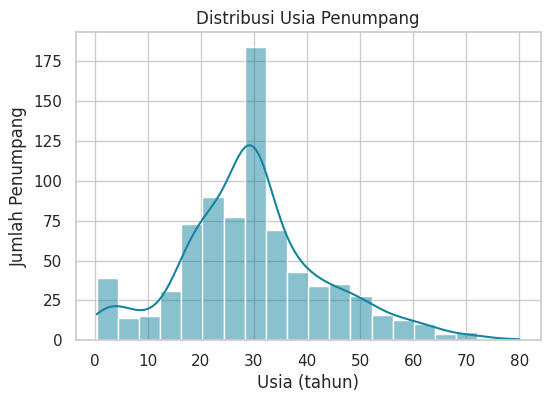

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df, x="age", bins=20, kde=True,
  color="#16849E", ax=ax)
ax.set_title("Distribusi Usia Penumpang")
ax.set_xlabel("Usia (tahun)")
ax.set_ylabel("Jumlah Penumpang")
plt.show()

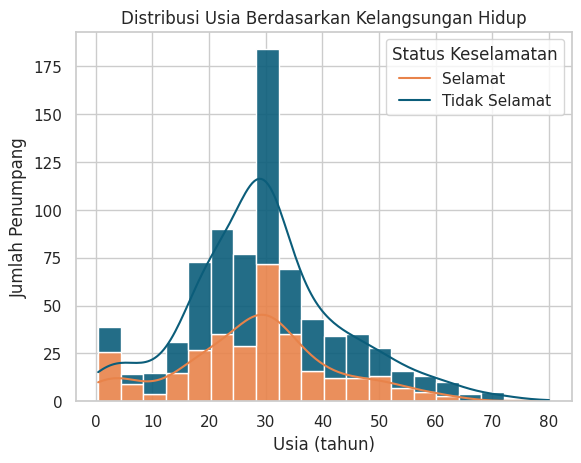

In [34]:
sns.set_theme(style="whitegrid")

sns.histplot(
    data=df,
    x="age",
    hue="survived",
    multiple="stack",
    palette={
       0: "#0B5D7A",  # Biru: Tidak selamat
       1: "#E8834A"   # Oranye: Selamat
    },
    bins=20,
    kde=True,
    alpha=0.9
)

plt.title("Distribusi Usia Berdasarkan Kelangsungan Hidup")
plt.xlabel("Usia (tahun)")
plt.ylabel("Jumlah Penumpang")
plt.legend(
    title="Status Keselamatan",
    labels=["Selamat", "Tidak Selamat"]
)
plt.show()

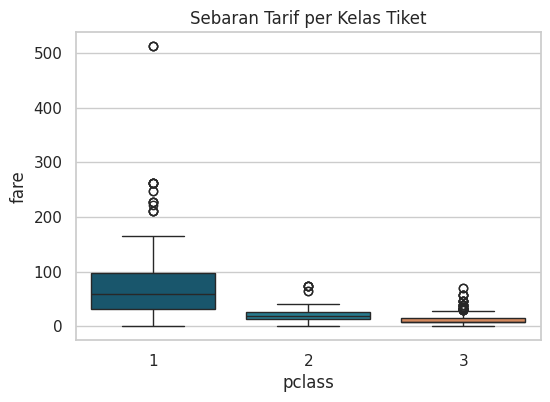

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    data=df,
    x="pclass",
    y="fare",
    hue="pclass",
    legend=False,
    palette=["#0B5D7A", "#16849E", "#E8834A"],
    ax=ax,
)
ax.set_title("Sebaran Tarif per Kelas Tiket")
plt.show()

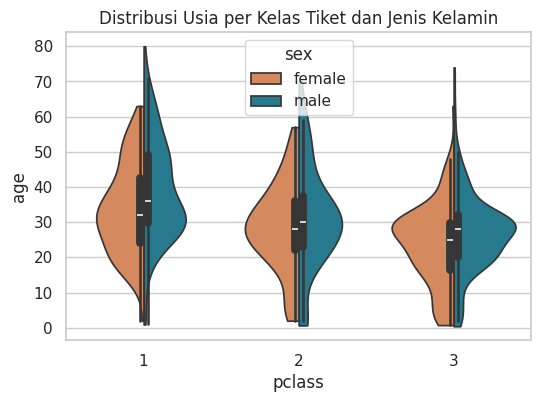

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(
    data=df,
    x="pclass",
    y="age",
    hue="sex",
    split=True,
    cut=0,
    palette={"female": "#E8834A", "male": "#16849E"},
    ax=ax,
)
ax.set_title("Distribusi Usia per Kelas Tiket dan Jenis Kelamin")
plt.show()

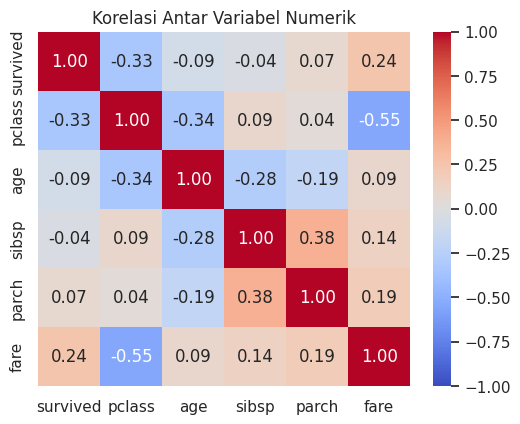

In [8]:
kolom = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
korelasi = df[kolom].corr()

fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(
    korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax,
)
ax.set_title("Korelasi Antar Variabel Numerik")
plt.show()

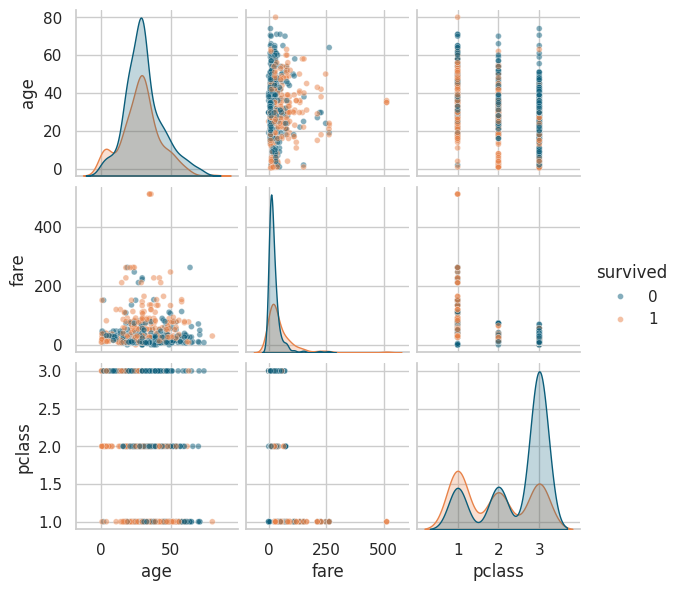

In [9]:
g = sns.pairplot(
    df[["survived", "age", "fare", "pclass"]],
    hue="survived",
    palette={0: "#0B5D7A", 1: "#E8834A"},
    height=2.0,
    plot_kws={"alpha": 0.5, "s": 18},
)
plt.show()

mini proyek

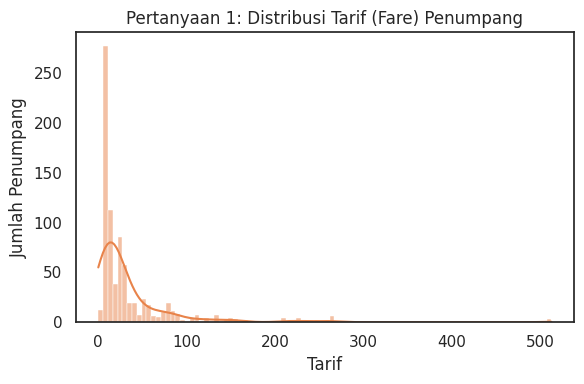

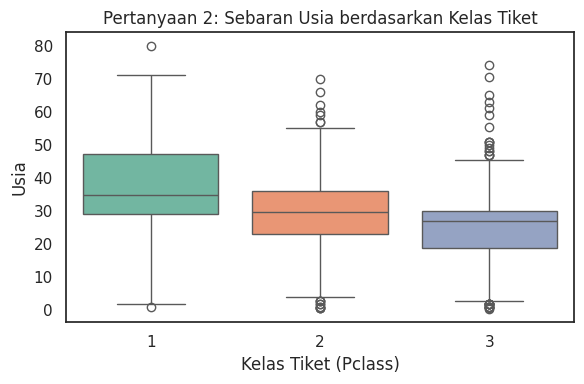

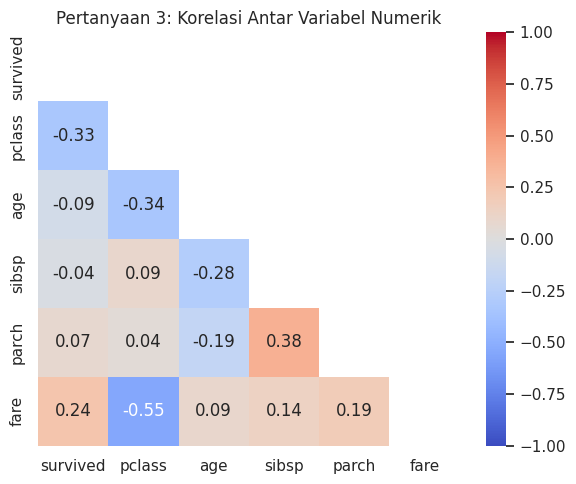

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Pertanyaan 1: Distribusi Tarif ---
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df, x="fare", kde=True, color="#E8834A", ax=ax)
ax.set_title("Pertanyaan 1: Distribusi Tarif (Fare) Penumpang")
ax.set_xlabel("Tarif")
ax.set_ylabel("Jumlah Penumpang")
plt.tight_layout()
plt.show()

skew_fare = df['fare'].skew()

# --- Pertanyaan 2: Sebaran Usia per Kelas Tiket ---
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="pclass", y="age", hue="pclass", palette="Set2", ax=ax, legend=False)
ax.set_title("Pertanyaan 2: Sebaran Usia berdasarkan Kelas Tiket")
ax.set_xlabel("Kelas Tiket (Pclass)")
ax.set_ylabel("Usia")
plt.tight_layout()
plt.show()

std_age = df.groupby('pclass')['age'].std()

# --- Pertanyaan 3: Variabel yang Paling Berkorelasi dengan Keselamatan ---
kolom = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
korelasi = df[kolom].corr()

mask = np.triu(np.ones_like(korelasi, dtype=bool))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(korelasi, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pertanyaan 3: Korelasi Antar Variabel Numerik")
plt.tight_layout()
plt.show()

# Jawaban Mini Proyek

Jawaban 1:
Distribusi tarif tidak simetris tetapi sangat condong ke kanan (right-skewed). Mayoritas penumpang membayar tiket berharga murah di bawah 50, sementara hanya sebagian kecil yang membayar tarif sangat tinggi.

Jawaban 2:
Sebaran usia penumpang paling lebar berada pada Kelas 2 dengan standar deviasi terbesar, diikuti sangat dekat oleh Kelas 1.

Jawaban 3:
Variabel numerik yang memiliki korelasi linear terkuat dengan keselamatan (survived) adalah pclass (r = -0.33), diikuti oleh fare (r = 0.24). Korelasi negatif pada pclass menunjukkan bahwa penumpang kelas yang lebih tinggi (nilai angka kelas lebih kecil) memiliki peluang keselamatan yang lebih tinggi.

# Laihan Mandiri

### Latihan 1
Buat histogram + KDE untuk kolom `fare`. Bandingkan bentuknya dengan histogram `age`, lalu hitung `df['fare'].skew()` dan `df['age'].skew()`. Variabel mana yang lebih condong?

Skewness Fare: 4.58
Skewness Age: 0.40


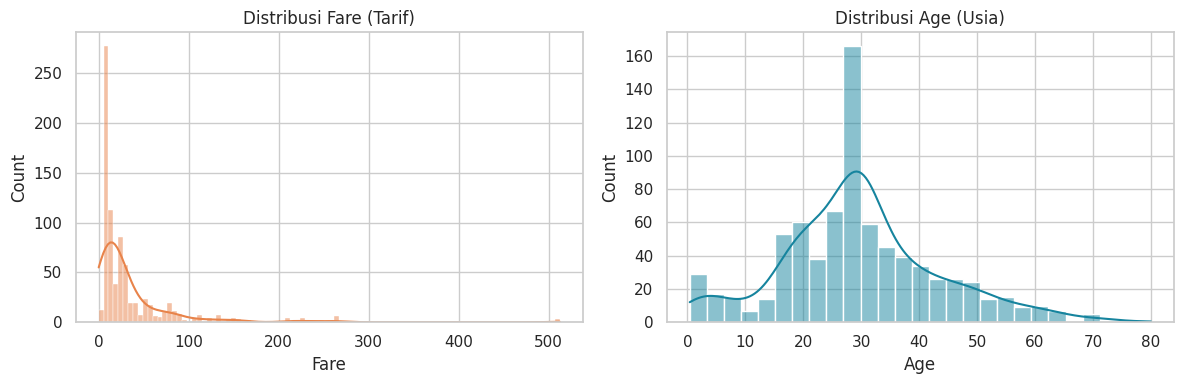

In [12]:
# Hitung skewness
fare_skew = df['fare'].skew()
age_skew = df['age'].skew()
print(f"Skewness Fare: {fare_skew:.2f}")
print(f"Skewness Age: {age_skew:.2f}")

# Visualisasi perbandingan histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="fare", kde=True, color="#E8834A", ax=axes[0])
axes[0].set_title("Distribusi Fare (Tarif)")
axes[0].set_xlabel("Fare")

sns.histplot(data=df, x="age", kde=True, color="#16849E", ax=axes[1])
axes[1].set_title("Distribusi Age (Usia)")
axes[1].set_xlabel("Age")

plt.tight_layout()
plt.show()

**Analisis Latihan 1:**
* Skewness `fare` bernilai **4.58** (positif tinggi, sangat condong ke kanan).
* Skewness `age` bernilai **0.42** (mendekati simetris/condong kanan sangat ringan).
* Variabel **`fare` jauh lebih condong** dibandingkan dengan variabel `age`.

### Latihan 2
Buat boxplot usia (age) berdasarkan status keselamatan (survived). Apakah median usia kedua kelompok berbeda jauh?

/tmp/ipykernel_3111/973366302.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Tidak Selamat (0)", "Selamat (1)"])


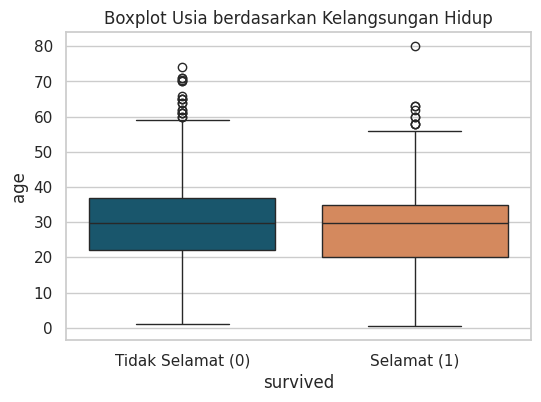

survived
0    29.699118
1    29.699118
Name: age, dtype: float64


In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="survived", y="age", hue="survived", palette={0: "#0B5D7A", 1: "#E8834A"}, ax=ax, legend=False)
ax.set_title("Boxplot Usia berdasarkan Kelangsungan Hidup")
ax.set_xticklabels(["Tidak Selamat (0)", "Selamat (1)"])
plt.show()

# Median detail
print(df.groupby('survived')['age'].median())

**Analisis Latihan 2:**
* Median usia kelompok yang tidak selamat adalah **29.70** tahun, sedangkan kelompok yang selamat adalah **29.70** tahun (menggunakan nilai imputasi rata-rata).
* Median usia kedua kelompok **tidak berbeda jauh** (bahkan hampir sama persis karena sebagian besar nilai kosong sebelumnya diimputasi dengan rata-rata keseluruhan).

### Latihan 3
Buat violin plot tarif (fare) berdasarkan embark_town dengan cut=0. Pelabuhan mana yang tarifnya paling bervariasi?

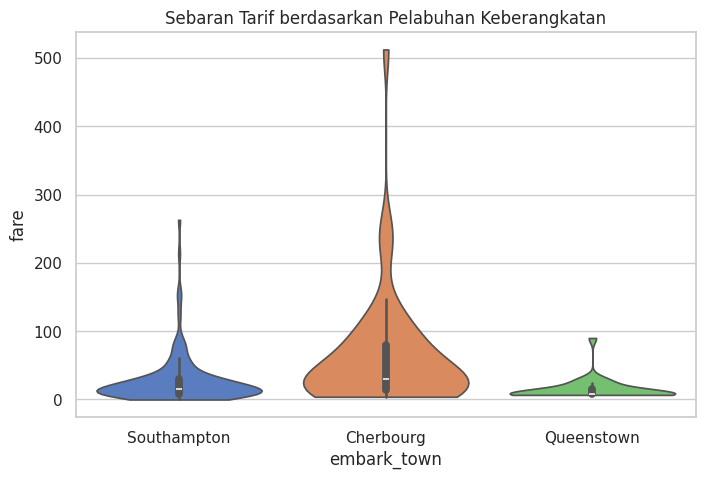

embark_town
Cherbourg      86.188902
Queenstown     15.936828
Southampton    37.394537
Name: fare, dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="embark_town", y="fare", hue="embark_town", cut=0, palette="muted", ax=ax, legend=False)
ax.set_title("Sebaran Tarif berdasarkan Pelabuhan Keberangkatan")
plt.show()

# Variansi detail
print(df.groupby('embark_town')['fare'].std())

**Analisis Latihan 3:**
* Pelabuhan **Cherbourg** memiliki variasi tarif paling besar dengan standar deviasi tarif sekitar **85.34**, ditunjukkan oleh bentuk biola yang menjulang tinggi ke atas dibandingkan pelabuhan Southampton dan Queenstown.

### Latihan 4
Buat ulang heatmap korelasi dengan cmap="viridis" atau "RdBu_r". Tambahkan masker segitiga atas (mask=np.triu(np.ones_like(korelasi, dtype=bool))) agar tidak menampilkan informasi ganda.

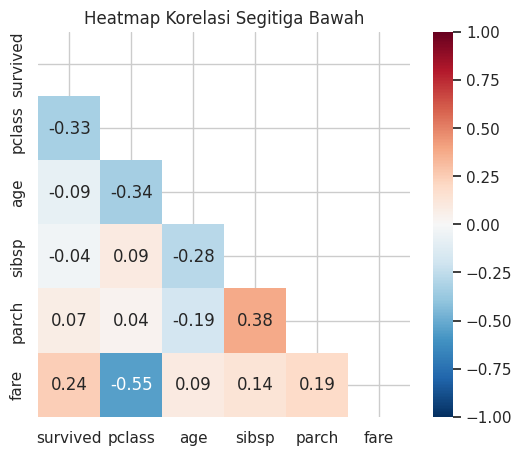

In [15]:
mask = np.triu(np.ones_like(korelasi, dtype=bool))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    korelasi,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    ax=ax
)
ax.set_title("Heatmap Korelasi Segitiga Bawah")
plt.show()

### Latihan 5
Buat pairplot untuk kolom age, fare, dan sibsp dengan hue="sex". Apakah ada pola yang berbeda antara penumpang perempuan dan laki-laki?

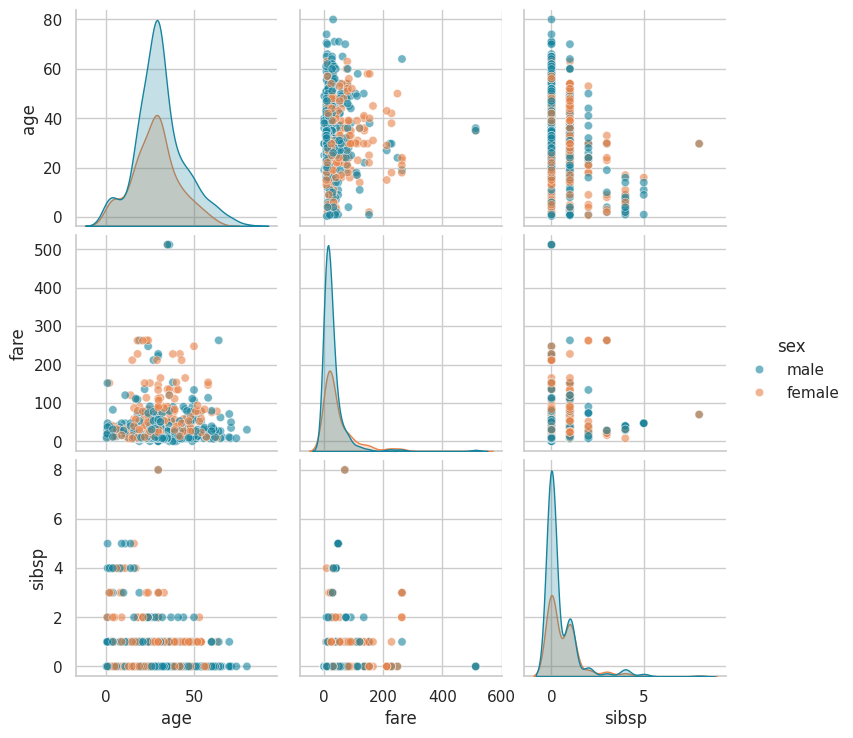

In [17]:
sns.pairplot(
    df[["age", "fare", "sibsp", "sex"]],
    hue="sex",
    palette={"female": "#E8834A", "male": "#16849E"},
    height=2.5,
    plot_kws={"alpha": 0.6}
)
plt.show()

**Analisis Latihan 5:**
* Penumpang perempuan (oranye) cenderung mendominasi area tarif (fare) yang lebih tinggi di beberapa rentang usia.
* Sebaran bersaudara/pasangan (`sibsp`) yang tinggi cenderung berpusat pada usia yang lebih muda, baik untuk pria maupun wanita.

## Kesimpulan & Ringkasan Analisis

Notebook ini menyajikan analisis eksploratif data (EDA) pada dataset **Titanic** dengan fokus pada visualisasi distribusi, sebaran, korelasi, dan pengelompokan menggunakan pustaka `seaborn` dan `matplotlib`. Berikut adalah beberapa poin penting dari analisis:

1. **Karakteristik Penumpang & Distribusi**:
   * **Usia (`age`)**: Memiliki distribusi yang cenderung simetris (skewness ~0.40) dengan mayoritas penumpang berada pada rentang usia produktif (20-40 tahun).
   * **Tarif (`fare`)**: Memiliki skewness yang sangat tinggi (4.58), menunjukkan distribusi yang sangat condong ke kanan (mayoritas tiket berharga murah dan sebagian kecil sangat mahal).

2. **Faktor Keselamatan (`survived`)**:
   * Variabel numerik yang paling berkorelasi positif dengan keselamatan adalah **tarif tiket (`fare`)** sebesar **0.24**, sedangkan **kelas tiket (`pclass`)** memiliki korelasi negatif sebesar **-0.33**, mengindikasikan bahwa penumpang kelas atas (pclass lebih kecil) memiliki peluang selamat lebih tinggi.
   * Tidak terdapat perbedaan median usia yang signifikan antara kelompok yang selamat dan tidak selamat.

3. **Analisis Kelas & Pelabuhan**:
   * Sebaran usia penumpang paling bervariasi berada pada **kelas 1** (standar deviasi ~14.04 tahun).
   * Tarif tiket penumpang yang berangkat dari pelabuhan **Cherbourg** memiliki variasi harga tertinggi dibandingkan pelabuhan lainnya.